In [28]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd() / "../src"))


import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from prepare_data import test_ds

In [29]:
ROOT = Path.cwd().parent
MODEL_PATH = ROOT / "models" / "cnn_model.keras"

CLASSES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]

In [30]:
model = tf.keras.models.load_model(MODEL_PATH)

In [31]:
image_batches = []
label_batches = []

for x, y in test_ds:
    image_batches.append(x.numpy())
    label_batches.append(y.numpy())

images = np.concatenate(image_batches)
y_true = np.concatenate(label_batches).reshape(-1)

In [32]:
y_pred = np.argmax(model.predict(images, verbose=0), axis=1)

In [33]:
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(classification_report(
    y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0
))

Accuracy: 0.8055
              precision    recall  f1-score   support

   buildings     0.7244    0.8175    0.7681       389
      forest     0.9354    0.9490    0.9422       412
     glacier     0.8451    0.6772    0.7519       443
    mountain     0.7833    0.7430    0.7626       467
         sea     0.7617    0.8539    0.8052       438
      street     0.8020    0.8080    0.8050       401

    accuracy                         0.8055      2550
   macro avg     0.8086    0.8081    0.8058      2550
weighted avg     0.8088    0.8055    0.8046      2550



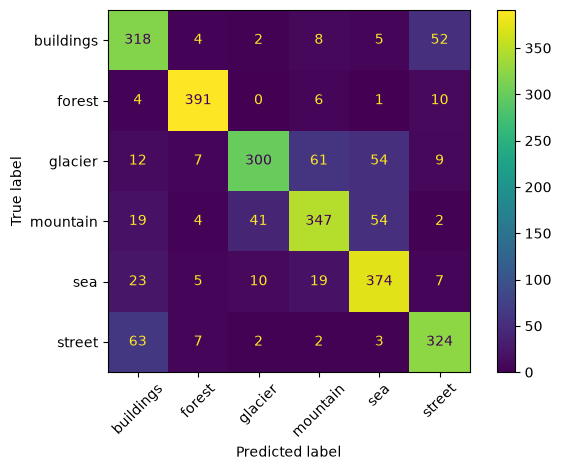

In [34]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm, display_labels=CLASSES)
disp.plot(xticks_rotation=45, values_format="d")
plt.tight_layout()
plt.show()
plt.close()


In [35]:
print("\nMost frequent confusions:")
errors = [
    (cm[i, j], CLASSES[i], CLASSES[j])
    for i in range(len(CLASSES))
    for j in range(len(CLASSES))
    if i != j and cm[i, j] > 0
]

for count, true_class, pred_class in sorted(errors, reverse=True)[:10]:
    print(f"{true_class} predicted as {pred_class}: {count}")



Most frequent confusions:
street predicted as buildings: 63
glacier predicted as mountain: 61
mountain predicted as sea: 54
glacier predicted as sea: 54
buildings predicted as street: 52
mountain predicted as glacier: 41
sea predicted as buildings: 23
sea predicted as mountain: 19
mountain predicted as buildings: 19
glacier predicted as buildings: 12


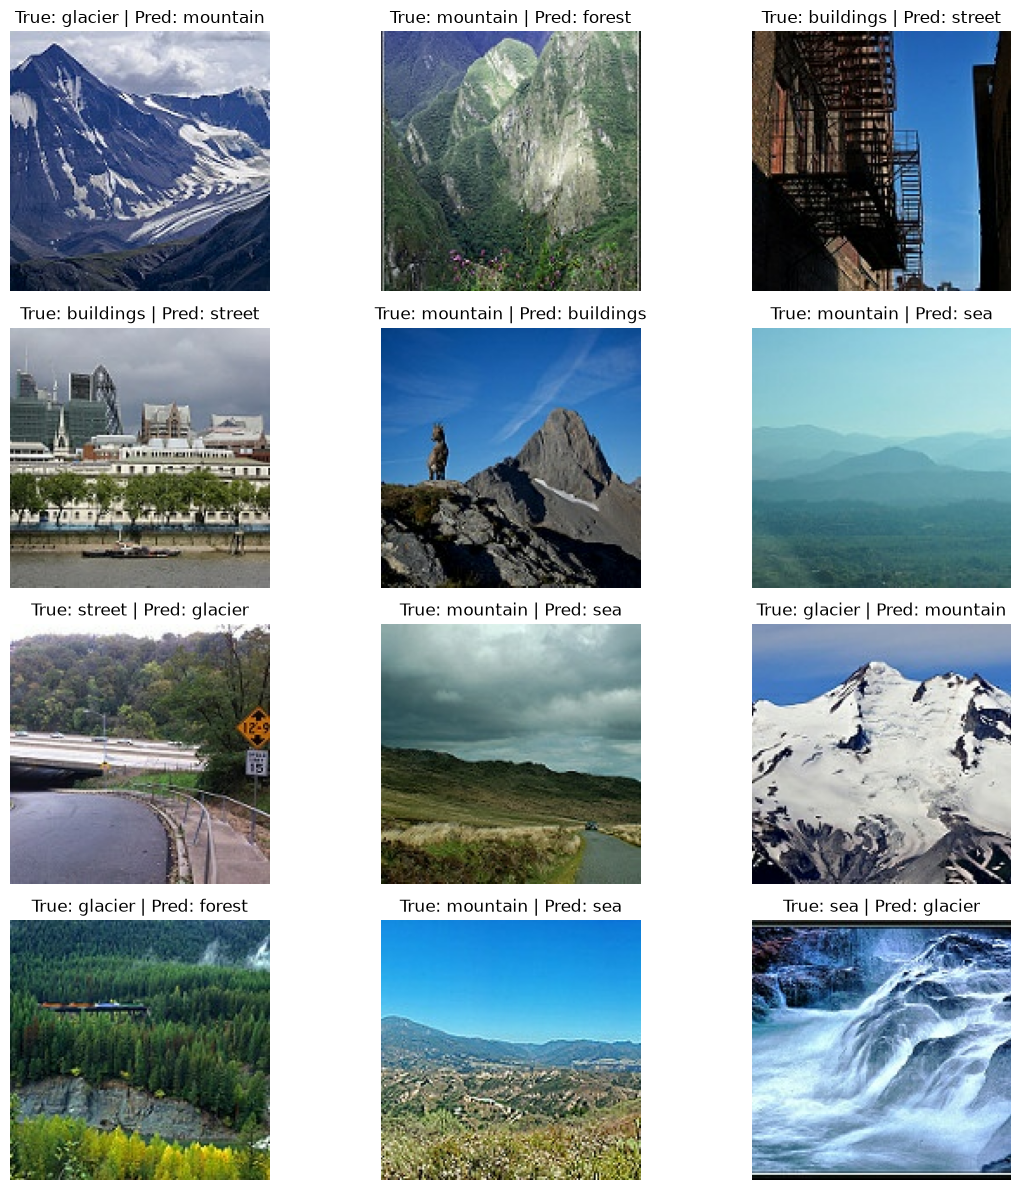

In [36]:
wrong = np.where(y_true != y_pred)[0][:12]

if len(wrong):
    fig, axes = plt.subplots(4, 3, figsize=(12, 12))

    for ax in axes.flat:
        ax.axis("off")

    for ax, i in zip(axes.flat, wrong):
        ax.imshow(np.clip(images[i], 0, 1))
        ax.set_title(f"True: {CLASSES[int(y_true[i])]} | Pred: {CLASSES[y_pred[i]]}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)